Eddy Guo                  eyguo-code                        8913122458                LLMs are used to compress some code cells to fit page limit

1.b.i.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
train = pd.read_csv("../Data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("../Data/aps_failure_test_set.csv", skiprows=20, na_values="na")
X_train, y_train = train.drop(columns="class"), train["class"]
X_test, y_test = test.drop(columns="class"), test["class"]
print(f"Missing values before imputation:\nTraining: {X_train.isna().sum().sum()}\nTest: {X_test.isna().sum().sum()}")
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)
print(f"\nMissing values after imputation:\nTraining: {X_train_imputed.isna().sum().sum()}\nTest: {X_test_imputed.isna().sum().sum()}")

Missing values before imputation:
Training: 850015
Test: 228680

Missing values after imputation:
Training: 0
Test: 0


1.b.ii.

In [ ]:
means = X_train_imputed.mean()
stds = X_train_imputed.std(ddof=1)
cv = stds / means
cv = cv.replace([np.inf, -np.inf], np.nan)
cv_results = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Mean": means.values,
    "Standard Deviation": stds.values,
    "CV": cv.values
})
print("Number of features:", len(cv_results))
display(cv_results)

Number of features: 170


,Feature,Mean,Standard Deviation,CV
0,aa_000,5.933650e+04,1.454301e+05,2.450938
1,ab_000,1.625000e-01,1.687318e+00,10.383494
2,ac_000,3.362258e+08,7.767625e+08,2.310241
3,ad_000,1.434383e+05,3.504525e+07,244.322816
4,ae_000,6.535000e+00,1.581479e+02,24.200137
...,...,...,...,...
165,ee_007,3.428586e+05,1.718666e+06,5.012754
166,ee_008,1.372212e+05,4.472145e+05,3.259079
167,ee_009,8.295099e+03,4.721249e+04,5.691612
168,ef_000,8.646667e-02,4.268570e+00,49.366659


1.c.iii.

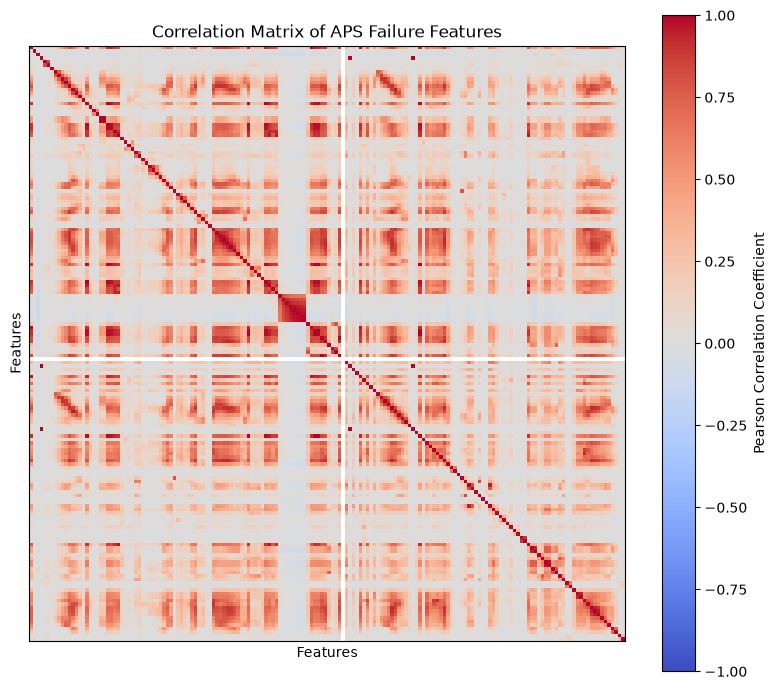

In [50]:
corr_matrix = X_train_imputed.corr()
plt.figure(figsize=(8, 7))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
plt.colorbar(label="Pearson Correlation Coefficient")
plt.title("Correlation Matrix of APS Failure Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

1.b.iv.

Top 13 features with highest CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


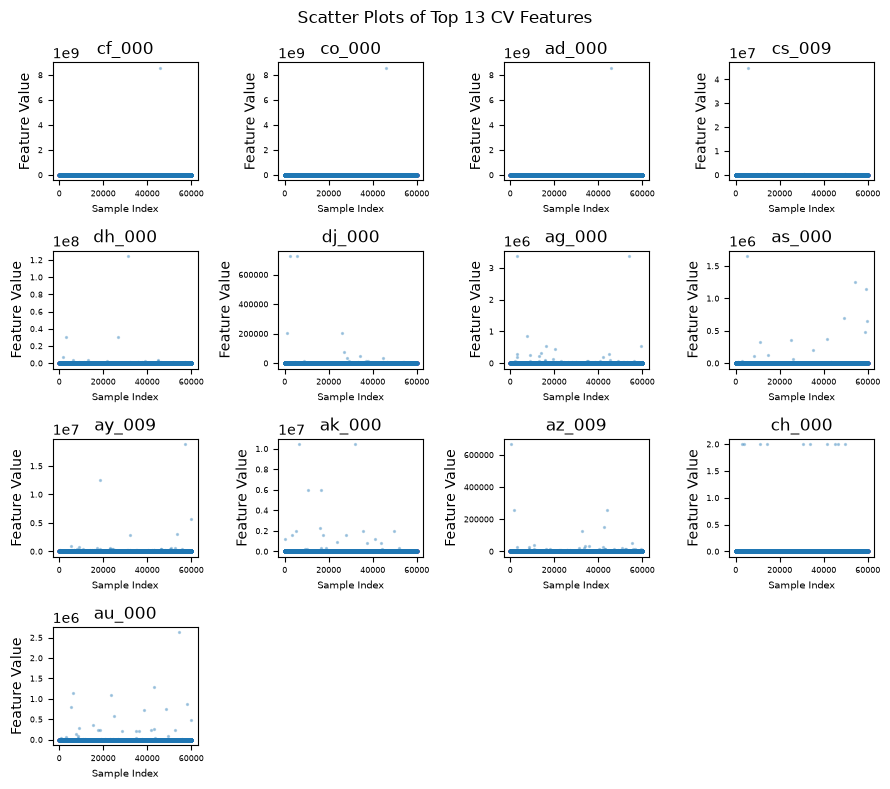

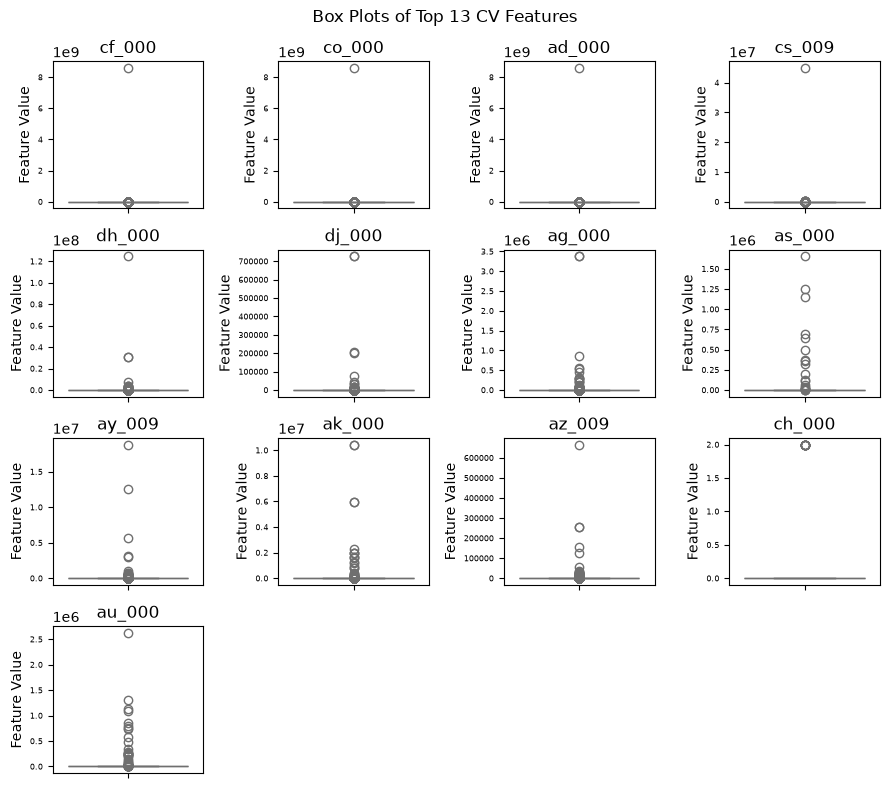

In [ ]:
n_features = int(np.floor(np.sqrt(170)))
top_features = cv_results.dropna(subset=["CV"]).nlargest(n_features, "CV")["Feature"].tolist()
print(f"Top {n_features} features with highest CV:\n{top_features}")
for kind, title in [("scatter", "Scatter Plots"), ("box", "Box Plots")]:
    fig, axes = plt.subplots(4, 4, figsize=(9, 8))
    for ax, feature in zip(axes.flat, top_features):
        if kind == "scatter":
            ax.scatter(X_train_imputed.index, X_train_imputed[feature], alpha=0.3, s=2)
            ax.set_xlabel("Sample Index", fontsize=7)
        else:
            sns.boxplot(y=X_train_imputed[feature], ax=ax, color="skyblue")
        ax.set(title=feature, ylabel="Feature Value")
        ax.tick_params(labelsize=6)
    for ax in list(axes.flat)[len(top_features):]:
        ax.axis("off")
    fig.suptitle(f"{title} of Top 13 CV Features", fontsize=12)
    plt.tight_layout()
    plt.show()

No, we cannot draw definitive conclusions about the significance of these features based solely on the scatter plots

1.c.

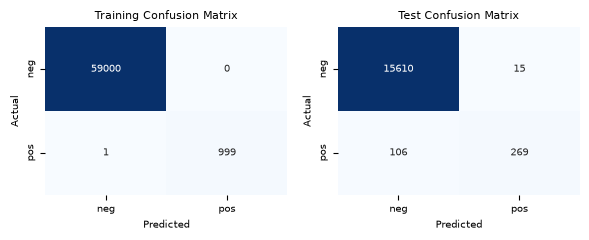

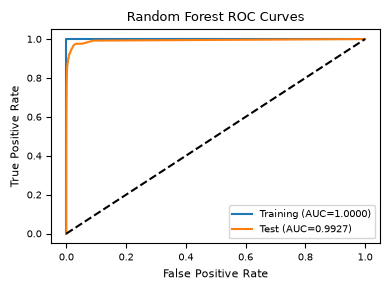

 Dataset      AUC  Misclassification Rate
Training 1.000000                0.000017
    Test 0.992745                0.007563

OOB Error: 0.0062
Test Error: 0.0076
Difference (OOB - Test): -0.0014


In [70]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, class_weight=None, random_state=42, n_jobs=-1)
rf.fit(X_train_imputed, y_train)
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
roc_fig, roc_ax = plt.subplots(figsize=(4, 3))
results = []
for ax, (X, y, name) in zip(axes, [(X_train_imputed, y_train, "Training"), (X_test_imputed, y_test, "Test")]):
    pred, prob = rf.predict(X), rf.predict_proba(X)[:, list(rf.classes_).index("pos")]
    sns.heatmap(confusion_matrix(y, pred, labels=["neg", "pos"]), annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"], ax=ax, annot_kws={"size": 7}, cbar=False)
    ax.set(title=f"{name} Confusion Matrix", xlabel="Predicted", ylabel="Actual")
    ax.title.set_fontsize(8)
    ax.xaxis.label.set_size(7)
    ax.yaxis.label.set_size(7)
    ax.tick_params(labelsize=7)
    fpr, tpr, _ = roc_curve(y == "pos", prob)
    auc = roc_auc_score(y == "pos", prob)
    roc_ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    results.append([name, auc, 1 - accuracy_score(y, pred)])
fig.tight_layout()
roc_ax.plot([0, 1], [0, 1], "k--")
roc_ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Random Forest ROC Curves")
roc_ax.title.set_fontsize(9)
roc_ax.xaxis.label.set_size(8)
roc_ax.yaxis.label.set_size(8)
roc_ax.tick_params(labelsize=7)
roc_ax.legend(fontsize=7)
roc_fig.tight_layout()
plt.show()
print(pd.DataFrame(results, columns=["Dataset", "AUC", "Misclassification Rate"]).to_string(index=False))
print(f"\nOOB Error: {1 - rf.oob_score_:.4f}")
print(f"Test Error: {results[1][2]:.4f}")
print(f"Difference (OOB - Test): {1 - rf.oob_score_ - results[1][2]:.4f}")

1.d.

c:\Users\eddy0\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


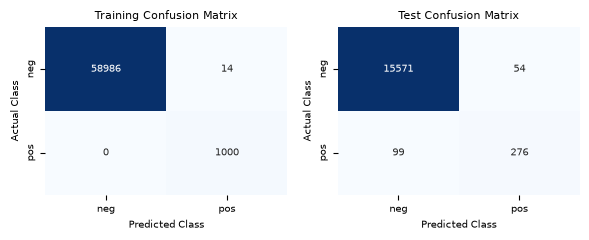

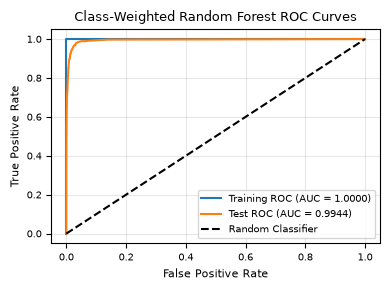


Class-Weighted Random Forest Performance:


,Metric,Training,Test
0,AUC,1.000000,0.994394
1,Misclassification Rate,0.000233,0.009563
2,Accuracy,0.999767,0.990438


OOB Error Estimate: 0.020217
Test Error:         0.009563
Difference:         0.010654


In [ ]:
rf_balanced = RandomForestClassifier(n_estimators=100, oob_score=True, bootstrap=True, class_weight="balanced", random_state=42, n_jobs=-1)
rf_balanced.fit(X_train_imputed, y_train)
y_train_pred, y_test_pred = rf_balanced.predict(X_train_imputed), rf_balanced.predict(X_test_imputed)
pos_idx = list(rf_balanced.classes_).index("pos")
y_train_prob, y_test_prob = rf_balanced.predict_proba(X_train_imputed)[:, pos_idx], rf_balanced.predict_proba(X_test_imputed)[:, pos_idx]
y_train_binary, y_test_binary = (y_train == "pos").astype(int), (y_test == "pos").astype(int)
labels = ["neg", "pos"]
cm_train, cm_test = confusion_matrix(y_train, y_train_pred, labels=labels), confusion_matrix(y_test, y_test_pred, labels=labels)
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
for ax, cm, title in zip(axes, [cm_train, cm_test], ["Training Confusion Matrix", "Test Confusion Matrix"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, annot_kws={"size": 7}, cbar=False)
    ax.set(title=title, xlabel="Predicted Class", ylabel="Actual Class")
    ax.title.set_fontsize(8)
    ax.xaxis.label.set_size(7)
    ax.yaxis.label.set_size(7)
    ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()
fpr_train, tpr_train, _ = roc_curve(y_train_binary, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test_binary, y_test_prob)
auc_train, auc_test = roc_auc_score(y_train_binary, y_train_prob), roc_auc_score(y_test_binary, y_test_prob)
plt.figure(figsize=(4, 3))
plt.plot(fpr_train, tpr_train, label=f"Training ROC (AUC = {auc_train:.4f})")
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {auc_test:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate", fontsize=8)
plt.ylabel("True Positive Rate", fontsize=8)
plt.title("Class-Weighted Random Forest ROC Curves", fontsize=9)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.legend(loc="lower right", fontsize=7)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
train_error, test_error, oob_error = 1 - accuracy_score(y_train, y_train_pred), 1 - accuracy_score(y_test, y_test_pred), 1 - rf_balanced.oob_score_
results_balanced = pd.DataFrame({"Metric": ["AUC", "Misclassification Rate", "Accuracy"], "Training": [auc_train, train_error, 1-train_error], "Test": [auc_test, test_error, 1-test_error]})
print("\nClass-Weighted Random Forest Performance:")
display(results_balanced.round(6))
print(f"OOB Error Estimate: {oob_error:.6f}\nTest Error:         {test_error:.6f}\nDifference:         {oob_error-test_error:.6f}")

The balanced Random Forest performs slightly worse in overall classification accuracy but better at identifying APS failures. This means that the balanced model is preferable under the dataset's cost function, although the unbalanced model achieves better overall accuracy and a lower test error.

1.e.

In [72]:
%%capture
%pip install xgboost

In [55]:
y_train_bin, y_test_bin = (y_train == "pos").astype(int), (y_test == "pos").astype(int)

xgb = XGBClassifier(booster="gbtree", objective="binary:logistic", tree_method="hist", n_estimators=100, max_depth=4, learning_rate=0.1, reg_lambda=1, scale_pos_weight=1, eval_metric="logloss", random_state=42, n_jobs=4)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(xgb, {"reg_alpha": [0, 0.01, 0.1, 1, 10]}, cv=cv, scoring="accuracy", n_jobs=1, verbose=2)
grid.fit(X_train_imputed, y_train_bin)
model = grid.best_estimator_

print(f"Best alpha: {grid.best_params_['reg_alpha']}\n5-Fold CV Error: {1-grid.best_score_:.6f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ........................................reg_alpha=0; total time=   0.7s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END ........................................reg_alpha=0; total time=   0.8s
[CV] END .....................................reg_alpha=0.01; total time=   0.8s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END .....................................reg_alpha=0.01; total time=   0.8s
[CV] END .....................................reg_alpha=0.01; total time=   0.7s
[CV] END ......................................reg_alpha=0.1; total time=   0.8s
[CV] END ......................................re

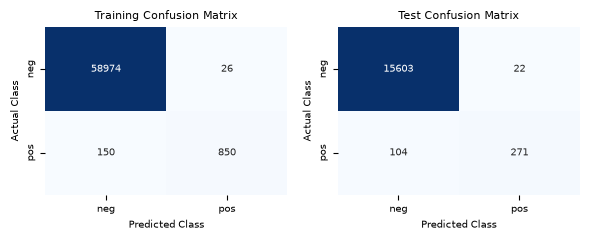

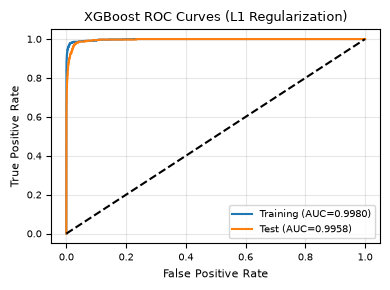

,Dataset,AUC,Misclassification Rate,Accuracy
0,Training,0.997996,0.002933,0.997067
1,Test,0.995812,0.007875,0.992125


Best Alpha:      1
5-Fold CV Error: 0.006367
Test Error:     0.007875
Difference:     -0.001508


In [67]:
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
roc_fig, roc_ax = plt.subplots(figsize=(4, 3))
results = []
for ax, (X, y, name) in zip(axes, [(X_train_imputed, y_train_bin, "Training"), (X_test_imputed, y_test_bin, "Test")]):
    pred, prob = model.predict(X), model.predict_proba(X)[:, 1]
    sns.heatmap(confusion_matrix(y, pred), annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"], ax=ax, annot_kws={"size": 7}, cbar=False)
    ax.set(title=f"{name} Confusion Matrix", xlabel="Predicted Class", ylabel="Actual Class")
    ax.title.set_fontsize(8)
    ax.xaxis.label.set_size(7)
    ax.yaxis.label.set_size(7)
    ax.tick_params(labelsize=7)
    fpr, tpr, _ = roc_curve(y, prob)
    auc, error = roc_auc_score(y, prob), 1 - accuracy_score(y, pred)
    roc_ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    results.append([name, auc, error, 1-error])
fig.tight_layout()
roc_ax.plot([0, 1], [0, 1], "k--")
roc_ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="XGBoost ROC Curves (L1 Regularization)")
roc_ax.title.set_fontsize(9)
roc_ax.xaxis.label.set_size(8)
roc_ax.yaxis.label.set_size(8)
roc_ax.tick_params(labelsize=7)
roc_ax.legend(fontsize=7)
roc_ax.grid(alpha=0.3)
roc_fig.tight_layout()
plt.show()
results_df = pd.DataFrame(results, columns=["Dataset", "AUC", "Misclassification Rate", "Accuracy"])
display(results_df.round(6))
cv_error, test_error = 1 - grid.best_score_, results[1][2]
print(f"Best Alpha:      {grid.best_params_['reg_alpha']}\n5-Fold CV Error: {cv_error:.6f}\nTest Error:     {test_error:.6f}\nDifference:     {cv_error-test_error:.6f}")

1.f.

In [71]:
%%capture
%pip install -q imbalanced-learn

In [58]:
y_train_bin, y_test_bin = (y_train == "pos").astype(int), (y_test == "pos").astype(int)

pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(booster="gbtree", objective="binary:logistic", tree_method="hist", n_estimators=100, max_depth=4, learning_rate=0.1, reg_lambda=1, scale_pos_weight=1, eval_metric="logloss", random_state=42, n_jobs=4))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_smote = GridSearchCV(pipeline, {"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]}, cv=cv, scoring="accuracy", n_jobs=1, verbose=2)
grid_smote.fit(X_train_imputed, y_train_bin)
model_smote = grid_smote.best_estimator_

print(f"Best alpha: {grid_smote.best_params_['xgb__reg_alpha']}\n5-Fold CV Error: {1-grid_smote.best_score_:.6f}")


Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   1.8s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.8s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.9s
[CV] END ................................xgb__reg_alpha=0.01; total time=   1.8s
[CV] END .................................xgb__reg_alpha=0.1; total time=   2.0s
[CV] END .................................xgb__re

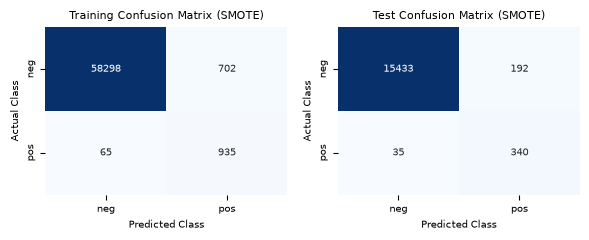

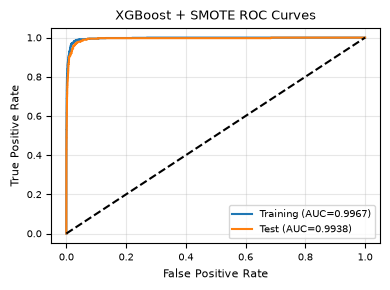

,Dataset,AUC,Misclassification Rate,Accuracy
0,Training,0.996737,0.012783,0.987217
1,Test,0.993828,0.014188,0.985812


Best Alpha:      0.01
5-Fold CV Error: 0.014867
Test Error:     0.014188
Difference:     0.000679


In [68]:
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
roc_fig, roc_ax = plt.subplots(figsize=(4, 3))
results_smote = []
for ax, (X, y, name) in zip(axes, [(X_train_imputed, y_train_bin, "Training"), (X_test_imputed, y_test_bin, "Test")]):
    pred, prob = model_smote.predict(X), model_smote.predict_proba(X)[:, 1]
    sns.heatmap(confusion_matrix(y, pred), annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"], ax=ax, annot_kws={"size": 7}, cbar=False)
    ax.set(title=f"{name} Confusion Matrix (SMOTE)", xlabel="Predicted Class", ylabel="Actual Class")
    ax.title.set_fontsize(8)
    ax.xaxis.label.set_size(7)
    ax.yaxis.label.set_size(7)
    ax.tick_params(labelsize=7)
    fpr, tpr, _ = roc_curve(y, prob)
    auc, error = roc_auc_score(y, prob), 1 - accuracy_score(y, pred)
    roc_ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    results_smote.append([name, auc, error, 1-error])
fig.tight_layout()
roc_ax.plot([0, 1], [0, 1], "k--")
roc_ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="XGBoost + SMOTE ROC Curves")
roc_ax.title.set_fontsize(9)
roc_ax.xaxis.label.set_size(8)
roc_ax.yaxis.label.set_size(8)
roc_ax.tick_params(labelsize=7)
roc_ax.legend(fontsize=7)
roc_ax.grid(alpha=0.3)
roc_fig.tight_layout()
plt.show()
results_smote_df = pd.DataFrame(results_smote, columns=["Dataset", "AUC", "Misclassification Rate", "Accuracy"])
display(results_smote_df.round(6))
cv_error_smote, test_error_smote = 1 - grid_smote.best_score_, results_smote[1][2]
print(f"Best Alpha:      {grid_smote.best_params_['xgb__reg_alpha']}\n5-Fold CV Error: {cv_error_smote:.6f}\nTest Error:     {test_error_smote:.6f}\nDifference:     {cv_error_smote-test_error_smote:.6f}")

### compare both

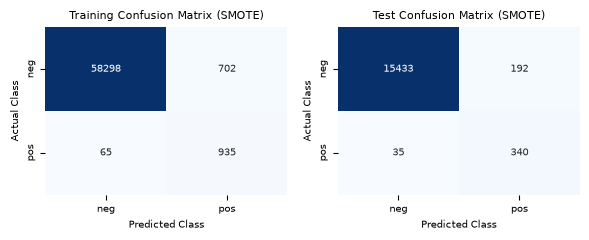

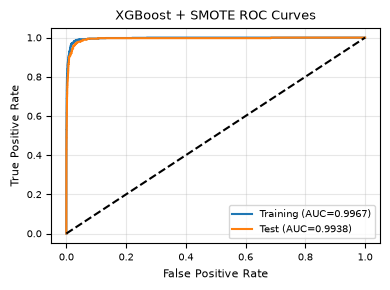

,Dataset,AUC,Misclassification Rate,Accuracy
0,Training,0.996737,0.012783,0.987217
1,Test,0.993828,0.014188,0.985812


Best Alpha:      0.01
5-Fold CV Error: 0.014867
Test Error:     0.014188
Difference:     0.000679


In [69]:
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
roc_fig, roc_ax = plt.subplots(figsize=(4, 3))
results_smote = []
for ax, (X, y, name) in zip(axes, [(X_train_imputed, y_train_bin, "Training"), (X_test_imputed, y_test_bin, "Test")]):
    pred, prob = model_smote.predict(X), model_smote.predict_proba(X)[:, 1]
    sns.heatmap(confusion_matrix(y, pred), annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"], ax=ax, annot_kws={"size": 7}, cbar=False)
    ax.set(title=f"{name} Confusion Matrix (SMOTE)", xlabel="Predicted Class", ylabel="Actual Class")
    ax.title.set_fontsize(8)
    ax.xaxis.label.set_size(7)
    ax.yaxis.label.set_size(7)
    ax.tick_params(labelsize=7)
    fpr, tpr, _ = roc_curve(y, prob)
    auc, error = roc_auc_score(y, prob), 1 - accuracy_score(y, pred)
    roc_ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    results_smote.append([name, auc, error, 1-error])
fig.tight_layout()
roc_ax.plot([0, 1], [0, 1], "k--")
roc_ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="XGBoost + SMOTE ROC Curves")
roc_ax.title.set_fontsize(9)
roc_ax.xaxis.label.set_size(8)
roc_ax.yaxis.label.set_size(8)
roc_ax.tick_params(labelsize=7)
roc_ax.legend(fontsize=7)
roc_ax.grid(alpha=0.3)
roc_fig.tight_layout()
plt.show()
results_smote_df = pd.DataFrame(results_smote, columns=["Dataset", "AUC", "Misclassification Rate", "Accuracy"])
display(results_smote_df.round(6))
cv_error_smote, test_error_smote = 1 - grid_smote.best_score_, results_smote[1][2]
print(f"Best Alpha:      {grid_smote.best_params_['xgb__reg_alpha']}\n5-Fold CV Error: {cv_error_smote:.6f}\nTest Error:     {test_error_smote:.6f}\nDifference:     {cv_error_smote-test_error_smote:.6f}")

2. 6.6.3.

(a) iv. Steadily decrease. Increasing \(s\) relaxes the constraint, allowing the model to fit training data better. Training RSS cannot increase.

(b) ii. U-shape. Initially. Initially, reduced bias improves predictions. Eventually, increased variance may cause overfitting, raising test RSS.

(c) iii. Steadily increase. Larger \(s\) allows greater model flexibility, making predictions more sensitive to training data.

(d) iv. Steadily decrease. As the constraint relaxes, coefficients are less restricted, reducing bias.

(e) v. Remain constant. Irreducible error is inherent in the data and does not depend on model complexity or regularization.

3. 6.6.5.


(a) Since $\hat{\beta}_0=0$, the ridge regression objective is

$\displaystyle \min_{\beta_1,\beta_2}\left[\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2+\lambda(\beta_1^2+\beta_2^2)\right].$

(b) Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, the objective becomes

$\displaystyle L=\sum_{i=1}^{2}(y_i-x_{i1}(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2).$

Taking partial derivatives and setting them to zero:

$\displaystyle \frac{\partial L}{\partial\beta_j}=-2\sum_{i=1}^{2}x_{i1}(y_i-x_{i1}(\beta_1+\beta_2))+2\lambda\beta_j=0,\quad j=1,2.$

Subtracting gives $2\lambda(\beta_1-\beta_2)=0$. Therefore, for $\lambda>0$, **$\boxed{\hat{\beta}_1=\hat{\beta}_2}$**.

(c) The lasso objective uses an absolute-value penalty:

$\displaystyle \min_{\beta_1,\beta_2}\left[\sum_{i=1}^{2}(y_i-x_{i1}(\beta_1+\beta_2))^2+\lambda(|\beta_1|+|\beta_2|)\right].$

(d) Since the predictors are identical, the RSS depends only on $c=\beta_1+\beta_2$. By the triangle inequality,

$\displaystyle |\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|c|.$

Equality holds when $\beta_1$ and $\beta_2$ have the same sign or one is zero. Thus, if $\hat c$ is the optimal coefficient sum, any pair satisfying $\beta_1+\beta_2=\hat c$ and $|\beta_1|+|\beta_2|=|\hat c|$ is optimal.

Equivalently, **$\boxed{(\hat{\beta}_1,\hat{\beta}_2)=(t\hat c,(1-t)\hat c),\quad 0\leq t\leq1}$**.

When $\hat c\neq0$, infinitely many coefficient pairs achieve the same minimum. If $\hat c=0$ and $\lambda>0$, the unique solution is $(0,0)$.


4. 8.4.5.


**Majority Vote**

Each tree predicts Red if $P(\text{Red}\mid X)>0.5$, otherwise Green.

Given probabilities: $0.1,\ 0.15,\ 0.2,\ 0.2,\ 0.55,\ 0.6,\ 0.6,\ 0.65,\ 0.7,\ 0.75$.

Red receives 6 votes and Green receives 4 votes.

Final Classification: $\boxed{\text{Red}}$

**Average Probability**

The average predicted probability of Red is

$\displaystyle \bar{P}(\text{Red}\mid X)=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=\frac{4.5}{10}=0.45.$

Since $0.45<0.5$, the final classification is **$\boxed{\text{Green}}$**.


5. 9.7.3

(a)

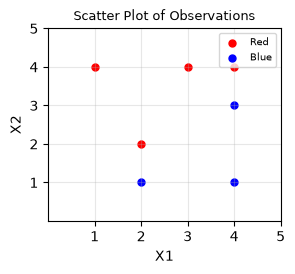

In [61]:
red, blue = [(3, 4), (2, 2), (4, 4), (1, 4)], [(2, 1), (4, 3), (4, 1)]
plt.figure(figsize=(3, 2.5))
for points, color in [(red, "red"), (blue, "blue")]:
    plt.scatter(*zip(*points), color=color, s=25, label=color.capitalize())
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Scatter Plot of Observations", fontsize=9)
plt.xticks(range(1, 6))
plt.yticks(range(1, 6))
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.legend(fontsize=7)
plt.show()

(b)

Equation: X_1 - X_2 = 0.5

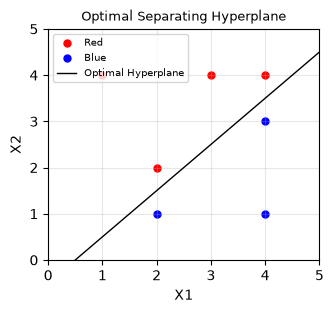

In [62]:
X = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y = np.array([1]*4 + [-1]*3)
svm = SVC(kernel="linear", C=1e6).fit(X, y)
w, b = svm.coef_[0], svm.intercept_[0]
x1 = np.linspace(0, 5, 200)

plt.figure(figsize=(3.5, 3))
for label, color in [(1, "red"), (-1, "blue")]:
    plt.scatter(X[y == label, 0], X[y == label, 1], color=color, s=25, label=color.capitalize())
plt.plot(x1, -(w[0]*x1+b)/w[1], "k-", linewidth=1, label="Optimal Hyperplane")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Optimal Separating Hyperplane", fontsize=9)
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xticks(range(6))
plt.yticks(range(6))
plt.grid(alpha=0.3)
plt.legend(fontsize=7)
plt.show()

(c)


The optimal separating hyperplane is $0.5-X_1+X_2=0$, with coefficients **$\boxed{\beta_0=0.5,\quad\beta_1=-1,\quad\beta_2=1}$**.

The classification rule is Red if $0.5-X_1+X_2>0$ and Blue otherwise.


(d) and (e)

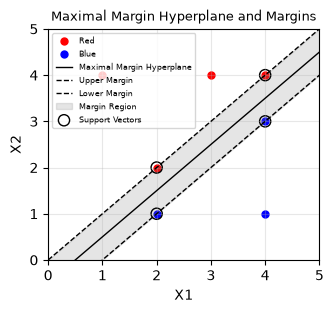

In [63]:
red, blue = np.array([[3,4], [2,2], [4,4], [1,4]]), np.array([[2,1], [4,3], [4,1]])
x = np.linspace(0, 5, 200)
plt.figure(figsize=(3.5, 3))
for points, color in [(red, "red"), (blue, "blue")]:
    plt.scatter(points[:,0], points[:,1], color=color, s=25, label=color.capitalize())
for y, style, label in [(x-0.5, "k-", "Maximal Margin Hyperplane"), (x, "k--", "Upper Margin"), (x-1, "k--", "Lower Margin")]:
    plt.plot(x, y, style, linewidth=1, label=label)
plt.fill_between(x, x-1, x, color="gray", alpha=0.2, label="Margin Region")
support = np.array([[2,2], [4,4], [2,1], [4,3]])
plt.scatter(support[:,0], support[:,1], s=65, facecolors="none", edgecolors="black", linewidths=1, label="Support Vectors")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Maximal Margin Hyperplane and Margins", fontsize=9)
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xticks(range(6))
plt.yticks(range(6))
plt.grid(alpha=0.3)
plt.legend(fontsize=6)
plt.show()

(f)

It is not a support vector, that is why its slight mopvement would not affect the maximal margin hyperplane.

(g)

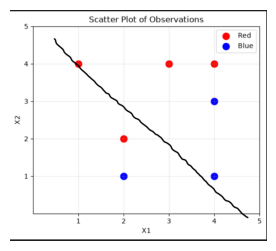

In [64]:
image = mpimg.imread("HW6_5_g.png")
plt.figure(figsize=(4, 3))
plt.imshow(image)
plt.axis("off")
plt.show()

(h)

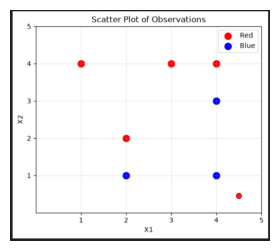

In [65]:
image = mpimg.imread("HW6_5_h.png")
plt.figure(figsize=(4, 3))
plt.axis("off")
plt.imshow(image)